# Statistical Inference and Temporal Trends

**Authors:** Mykhailo Mas, Adam Nolan.

## 1. Confidence Intervals for Biodiversity Indicators

Annual estimates give equal weight to each contributing route. We use
95% Student's t-confidence intervals based on variation among route-level
values, excluding missing values separately for each indicator.

Route-based intervals assume independent routes and describe the monitored network; they do not correct imperfect detection or spatial dependence.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

# The same plain plotting defaults in both notebooks.
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "savefig.transparent": False,
    "savefig.dpi": 180, "axes.grid": True, "grid.alpha": 0.25,
})
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
years = np.arange(2014, 2026)

route_year = pd.read_csv(ROOT / "data/processed/route_year_indicators.csv")

indicators = ["richness", "recorded_abundance", "shannon"]
labels = {
    "richness": "Species richness",
    "recorded_abundance": "Recorded abundance",
    "shannon": "Shannon diversity",
}

print(route_year.shape)
display(route_year.head())
print(route_year.columns.tolist())
points = pd.read_csv(ROOT / "data/processed/point_surveys.csv")
points["date"] = pd.to_datetime(points["date"], format="mixed")
assert not route_year.duplicated(["route_key", "year"]).any()
assert set(route_year["year"]) == set(years)

(723, 5)


,route_key,year,richness,recorded_abundance,shannon
0,anse couleuvre,2014,4.500000,8.55,1.370119
1,anse couleuvre,2015,6.000000,9.65,1.577190
2,anse couleuvre,2016,5.500000,8.95,1.572054
3,anse couleuvre,2017,4.294118,7.10,1.299908
4,anse couleuvre,2018,3.941176,6.85,1.179100


['route_key', 'year', 'richness', 'recorded_abundance', 'shannon']


In [2]:
def t_confidence_interval(estimate, standard_error, df, confidence=0.95):
    """Two-sided Student's t interval with the supplied degrees of freedom."""
    critical_value = stats.t.ppf(1 - (1 - confidence) / 2, df=df)
    margin = critical_value * standard_error
    return estimate - margin, estimate + margin


def mean_confidence_interval(values, confidence=0.95):
    """Mean and t interval after omitting missing values; n < 2 has no interval."""
    values = pd.Series(values).dropna()
    n = len(values)
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(n) if n >= 2 else np.nan
    lower, upper = (
        t_confidence_interval(mean, se, df=n - 1, confidence=confidence)
        if n >= 2 else (np.nan, np.nan)
    )
    return pd.Series({
        "mean": mean,
        "n": n,
        "se": se,
        "ci_lower": lower,
        "ci_upper": upper,
    })


def annual_confidence_intervals(data, value_column):
    """Summarize one value per route-year, giving each route equal weight."""
    return (
        data.groupby("year", sort=True)[value_column]
        .apply(mean_confidence_interval)
        .unstack()
        .reset_index()
    )

### Route-Level Species Richness in 2014

In [3]:
richness_2014 = route_year.loc[route_year["year"].eq(2014), "richness"].dropna()
richness_summary = mean_confidence_interval(richness_2014)

print(f"Number of routes: {len(richness_2014)}")
print(f"Mean species richness: {richness_summary['mean']:.4f}")
print(f"Sample standard deviation: {richness_2014.std(ddof=1):.4f}")
print(f"Standard error: {richness_summary['se']:.4f}")
print(
    f"95% confidence interval: "
    f"[{richness_summary['ci_lower']:.4f}, {richness_summary['ci_upper']:.4f}]"
)

Number of routes: 40
Mean species richness: 6.4322
Sample standard deviation: 1.7848
Standard error: 0.2822
95% confidence interval: [5.8614, 7.0030]


### Annual Estimates, 2014–2025

In [4]:
ci_tables = {
    indicator: annual_confidence_intervals(route_year, indicator)
    for indicator in indicators
}

for indicator, table in ci_tables.items():
    print(f"\n{indicator.upper()}")
    display(table.round(4))


RICHNESS


,year,mean,n,se,ci_lower,ci_upper
0,2014,6.4322,40.0,0.2822,5.8614,7.0030
1,2015,7.3533,53.0,0.2085,6.9350,7.7716
2,2016,7.7539,59.0,0.1994,7.3549,8.1530
3,2017,7.7253,60.0,0.2405,7.2441,8.2066
4,2018,7.4403,64.0,0.2113,7.0180,7.8626
5,2019,7.5680,64.0,0.2150,7.1384,7.9976
6,2020,8.3918,63.0,0.2188,7.9543,8.8292
7,2021,8.3256,63.0,0.2582,7.8095,8.8417
8,2022,8.3034,63.0,0.2736,7.7565,8.8503
9,2023,7.9920,64.0,0.2438,7.5048,8.4793



RECORDED_ABUNDANCE


,year,mean,n,se,ci_lower,ci_upper
0,2014,14.0114,40.0,0.9017,12.1876,15.8351
1,2015,16.2893,53.0,0.8967,14.4899,18.0887
2,2016,16.5122,59.0,0.7485,15.0139,18.0105
3,2017,17.5533,60.0,1.1306,15.2910,19.8157
4,2018,15.8406,64.0,0.8590,14.1241,17.5572
5,2019,16.9029,64.0,0.8772,15.1499,18.6559
6,2020,18.7225,63.0,0.9383,16.8470,20.5980
7,2021,19.0750,63.0,0.9939,17.0883,21.0617
8,2022,19.2121,63.0,1.0407,17.1316,21.2925
9,2023,17.8477,64.0,0.9555,15.9383,19.7571



SHANNON


,year,mean,n,se,ci_lower,ci_upper
0,2014,1.6665,39.0,0.0313,1.6031,1.7299
1,2015,1.7677,53.0,0.0245,1.7185,1.8170
2,2016,1.8299,59.0,0.0251,1.7795,1.8802
3,2017,1.8136,60.0,0.0298,1.7540,1.8733
4,2018,1.7679,64.0,0.0295,1.7089,1.8269
5,2019,1.7796,64.0,0.0292,1.7212,1.8380
6,2020,1.8948,63.0,0.0277,1.8394,1.9503
7,2021,1.8738,63.0,0.0326,1.8086,1.9390
8,2022,1.8760,63.0,0.0333,1.8094,1.9427
9,2023,1.8415,64.0,0.0315,1.7785,1.9045


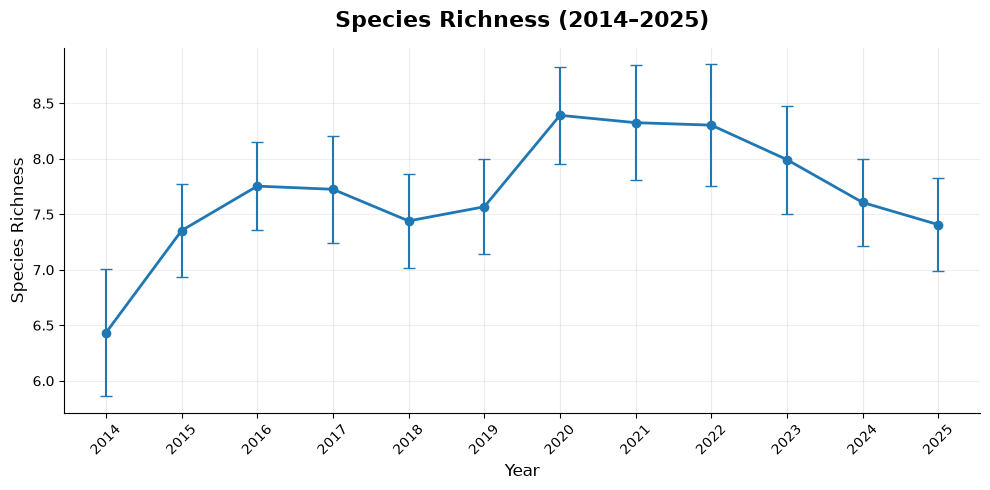

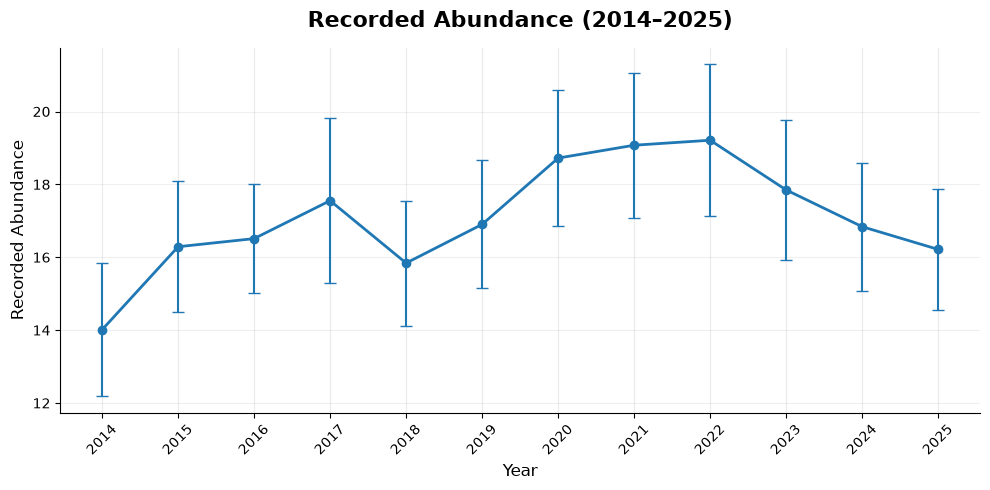

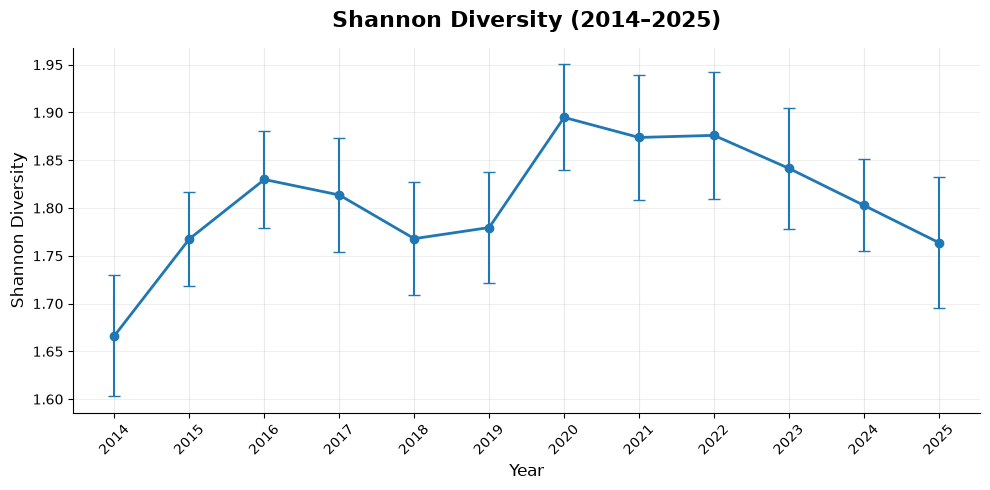

In [5]:
for indicator, table in ci_tables.items():

    lower_error = table["mean"] - table["ci_lower"]
    upper_error = table["ci_upper"] - table["mean"]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.errorbar(
        table["year"],
        table["mean"],
        yerr=[lower_error, upper_error],
        fmt="o-",
        capsize=4,
        markersize=6,
        linewidth=2,
        elinewidth=1.5
    )

    ax.set_title(
        f"{labels[indicator].title()} (2014–2025)",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel(labels[indicator].title(), fontsize=12)

    ax.set_xticks(range(2014, 2026))
    ax.tick_params(axis="x", rotation=45)

    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        FIGURES / f"{indicator}_confidence_intervals.png",
        bbox_inches="tight"
    )

    plt.show()

## 2. Temporal Trend Analysis

### Linear Regression

We fit an unweighted linear regression to the 12 annual means:

$$
Y_y = \beta_0 + \beta_1(y - 2014) + \epsilon_y.
$$

The slope $\beta_1$ represents annual change. We test
$H_0: \beta_1 = 0$ against $H_1: \beta_1 \ne 0$, then examine whether
a quadratic model better describes the temporal pattern.

In [6]:
linear_models = {
    indicator: stats.linregress(table["year"] - 2014, table["mean"])
    for indicator, table in ci_tables.items()
}
richness_trend = linear_models["richness"]

print(f"Intercept: {richness_trend.intercept:.4f}")
print(f"Slope: {richness_trend.slope:.4f} species per year")
print(f"R-squared: {richness_trend.rvalue**2:.4f}")
print(f"P-value: {richness_trend.pvalue:.4f}")
print(f"Standard error of slope: {richness_trend.stderr:.4f}")

Intercept: 7.2871
Slope: 0.0735 species per year
R-squared: 0.2395
P-value: 0.1064
Standard error of slope: 0.0414


The fitted mean richness in 2014 is 7.2871 species. The estimated slope
is 0.0735 species per year, and $R^2 = 0.2395$: time explains about 24%
of the variation among annual means.

With $p = 0.1064$, we do not reject a zero slope at the 5% level.
This does not establish the absence of a trend.

### 95% Confidence Interval for the Slope

In [7]:
slope_ci_lower, slope_ci_upper = t_confidence_interval(
    richness_trend.slope,
    richness_trend.stderr,
    df=len(ci_tables["richness"]) - 2,
)
print(f"95% CI for slope: [{slope_ci_lower:.4f}, {slope_ci_upper:.4f}]")

95% CI for slope: [-0.0188, 0.1659]


Simple linear regression has $n - 2 = 10$ residual degrees of freedom:

$$
\hat{\beta}_1 \pm t_{0.975,10}\,SE(\hat{\beta}_1)
\approx 0.0735 \pm 2.228 \times 0.04144
= [-0.0188,\ 0.1659].
$$

In [8]:
trend_results = pd.DataFrame([
    {
        "indicator": indicator,
        "slope": result.slope,
        "intercept": result.intercept,
        "r_squared": result.rvalue**2,
        "p_value": result.pvalue,
        "slope_se": result.stderr,
    }
    for indicator, result in linear_models.items()
])
trend_results["slope_ci_lower"], trend_results["slope_ci_upper"] = t_confidence_interval(
    trend_results["slope"], trend_results["slope_se"], df=len(years) - 2,
)
display(trend_results.round(4))

,indicator,slope,intercept,r_squared,p_value,slope_se,slope_ci_lower,slope_ci_upper
0,richness,0.0735,7.2871,0.2395,0.1064,0.0414,-0.0188,0.1659
1,recorded_abundance,0.2041,15.9628,0.2404,0.1056,0.1147,-0.0515,0.4597
2,shannon,0.0077,1.7639,0.1939,0.1520,0.0050,-0.0034,0.0189


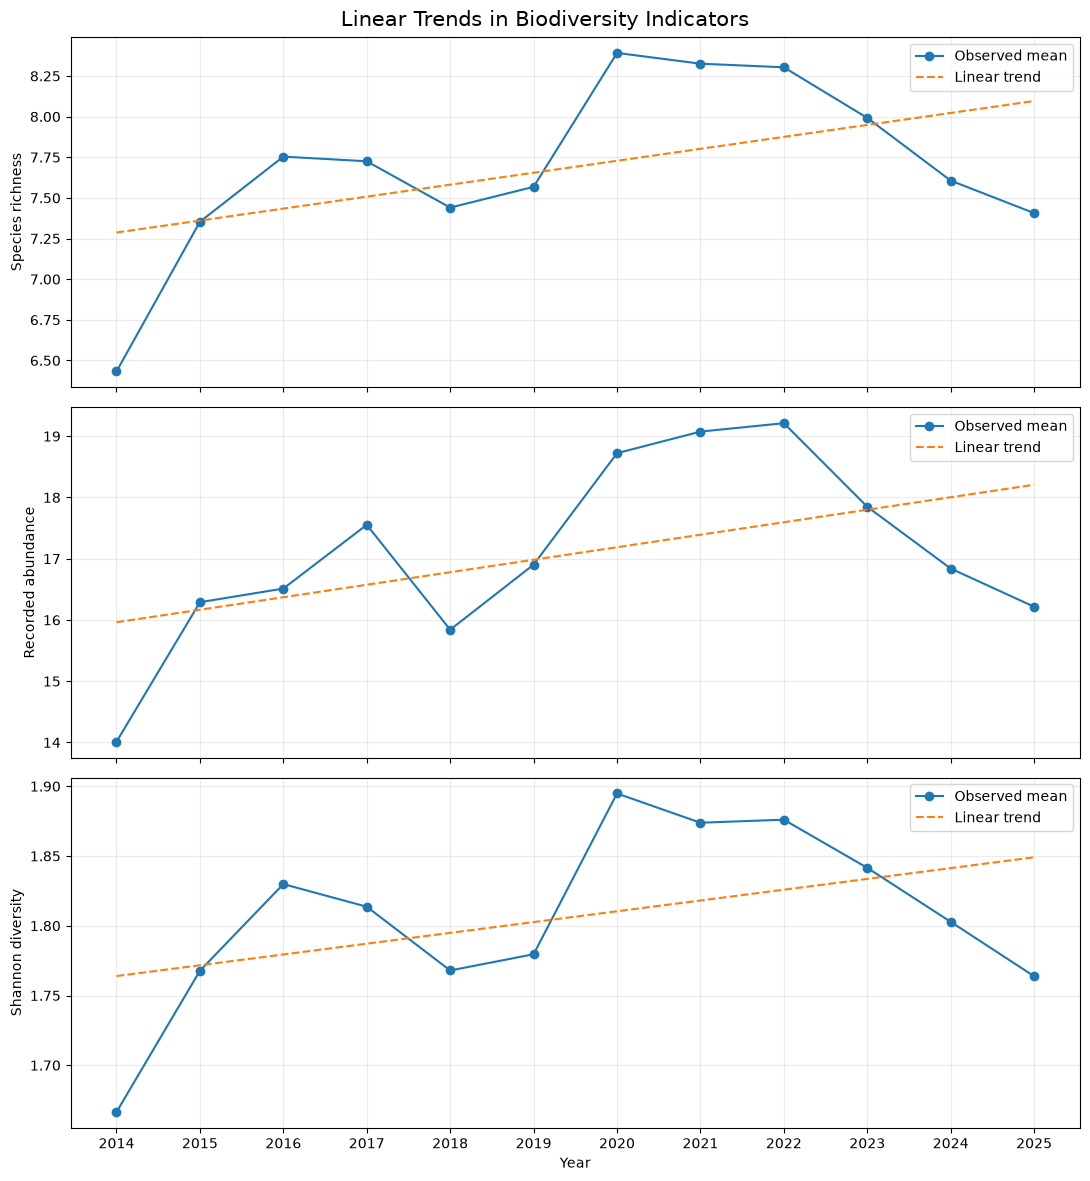

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, indicator in zip(axes, indicators):
    table = ci_tables[indicator]

    x = table["year"] - 2014
    y = table["mean"]

    result = linear_models[indicator]

    y_fitted = result.intercept + result.slope * x

    ax.plot(table["year"], y, "o-", label="Observed mean")
    ax.plot(table["year"], y_fitted, "--", label="Linear trend")

    ax.set_ylabel(labels[indicator])
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))

fig.suptitle("Linear Trends in Biodiversity Indicators", fontsize=15)

plt.tight_layout()
fig.savefig(FIGURES / "linear_trends.png", bbox_inches="tight")
plt.show()

### 2.1 Quadratic Trend Analysis

Annual estimates peak around 2020–2022. We compare two nested models:

$$
\begin{aligned}
\text{Linear:}\quad &Y(t) = \beta_0 + \beta_1 t + \epsilon,\\
\text{Quadratic:}\quad &Y(t) = \beta_0 + \beta_1 t + \beta_2 t^2 + \epsilon,
\end{aligned}
$$

where $t = \text{year} - 2014$. A nested-model F-test assesses the
additional quadratic term. Turning years are reported only within 2014–2025.

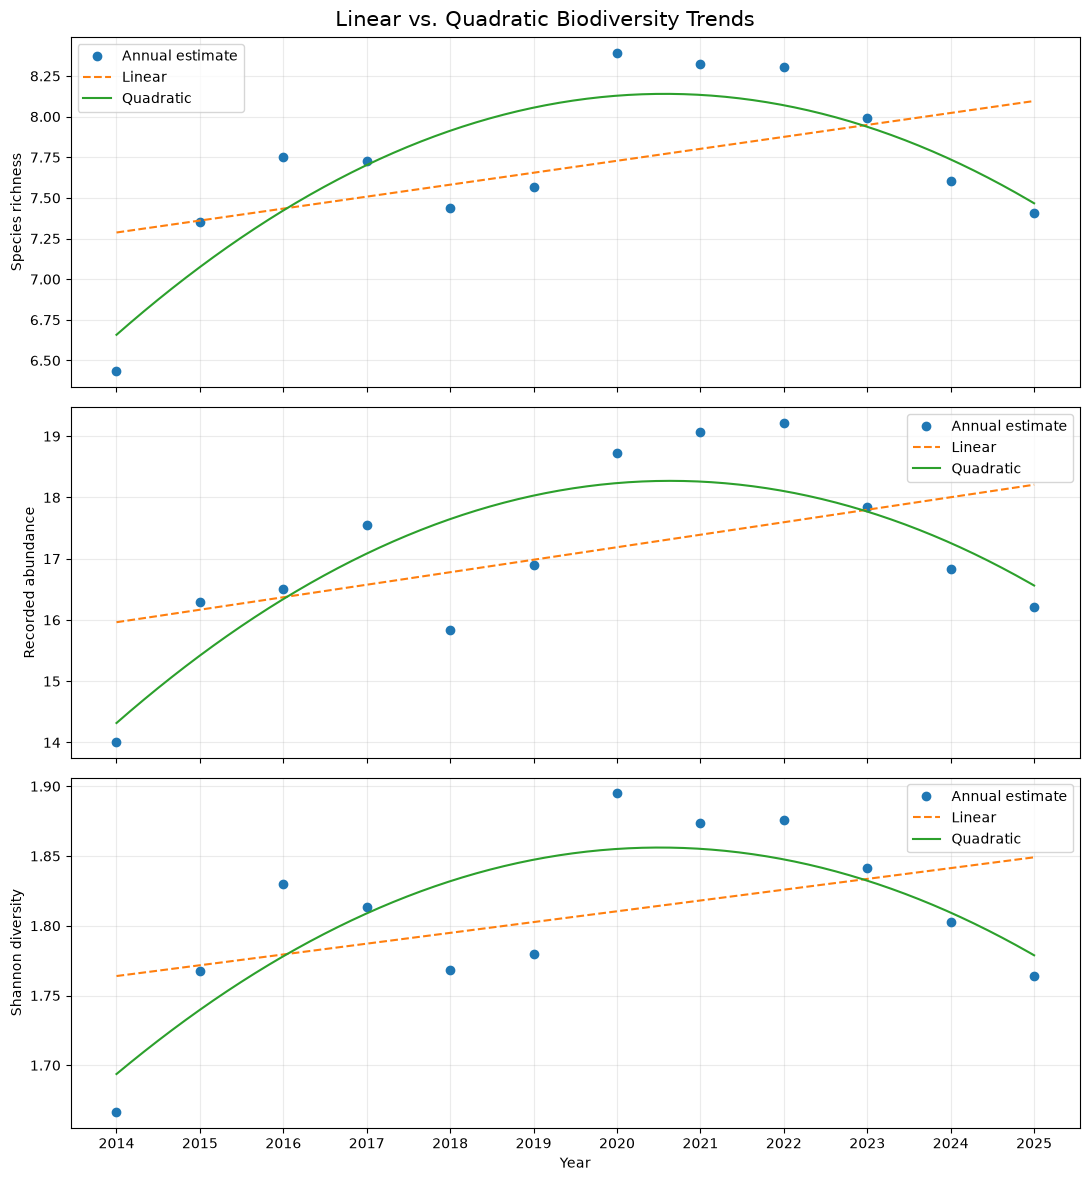

,indicator,beta_0,beta_1,beta_2,r2_linear,r2_quadratic,F_statistic,p_value,turning_year
0,richness,6.6579,0.4511,-0.0343,0.2395,0.7263,16.0107,0.0031,2020.5714
1,recorded_abundance,14.3173,1.1914,-0.0898,0.2404,0.6744,11.9985,0.0071,2020.6367
2,shannon,1.6937,0.0499,-0.0038,0.1939,0.6375,11.0157,0.0090,2020.5098


In [10]:
def fit_polynomial_trend(t, y, degree):
    """Fit an unweighted polynomial by least squares, retaining residuals."""
    design = np.column_stack([np.ones(len(t)), *[t**k for k in range(1, degree + 1)]])
    coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - design @ coefficients
    rss = np.sum(residuals**2)
    return {
        "coefficients": coefficients,
        "residuals": residuals,
        "rss": rss,
        "df": len(y) - design.shape[1],
        "r_squared": 1 - rss / np.sum((y - y.mean())**2),
    }


def nested_f_test(reduced, full):
    """Compare nested least-squares fits to the same observations."""
    df_difference = reduced["df"] - full["df"]
    statistic = ((reduced["rss"] - full["rss"]) / df_difference) / (
        full["rss"] / full["df"]
    )
    return statistic, stats.f.sf(statistic, df_difference, full["df"])


polynomial_models = {}
quadratic_results = []

for indicator, table in ci_tables.items():
    t = (table["year"] - 2014).to_numpy()
    y = table["mean"].to_numpy()
    linear = fit_polynomial_trend(t, y, degree=1)
    quadratic = fit_polynomial_trend(t, y, degree=2)
    polynomial_models[indicator] = {"linear": linear, "quadratic": quadratic}
    f_statistic, p_value = nested_f_test(linear, quadratic)

    beta = quadratic["coefficients"]
    turning_year = np.nan
    if not np.isclose(beta[2], 0):
        candidate = 2014 - beta[1] / (2 * beta[2])
        if 2014 <= candidate <= 2025:
            turning_year = candidate

    quadratic_results.append({
        "indicator": indicator,
        "beta_0": beta[0], "beta_1": beta[1], "beta_2": beta[2],
        "r2_linear": linear["r_squared"],
        "r2_quadratic": quadratic["r_squared"],
        "F_statistic": f_statistic,
        "p_value": p_value,
        "turning_year": turning_year,
    })

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
for ax, indicator in zip(axes, indicators):
    table = ci_tables[indicator]
    t = (table["year"] - 2014).to_numpy()
    t_fine = np.linspace(t.min(), t.max(), 200)
    beta_linear = polynomial_models[indicator]["linear"]["coefficients"]
    beta_quad = polynomial_models[indicator]["quadratic"]["coefficients"]

    ax.plot(table["year"], table["mean"], "o", label="Annual estimate")
    ax.plot(
        2014 + t_fine, beta_linear[0] + beta_linear[1] * t_fine,
        "--", label="Linear",
    )
    ax.plot(
        2014 + t_fine, beta_quad[0] + beta_quad[1] * t_fine + beta_quad[2] * t_fine**2,
        "-", label="Quadratic",
    )
    ax.set_ylabel(labels[indicator])
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))
fig.suptitle("Linear vs. Quadratic Biodiversity Trends", fontsize=15)
plt.tight_layout()
fig.savefig(FIGURES / "quadratic_trends.png", bbox_inches="tight")
plt.show()

quadratic_results = pd.DataFrame(quadratic_results)
display(quadratic_results.round(4))

### 2.2 Residual Autocorrelation: Durbin–Watson Statistic

$$
DW = \frac{\sum_{t=2}^{n}(\hat{\epsilon}_t - \hat{\epsilon}_{t-1})^2}
{\sum_{t=1}^{n}\hat{\epsilon}_t^2}.
$$

We examine first-order autocorrelation in the quadratic model residuals,
ordered by year. Values near 2 suggest little autocorrelation; values below
or above 2 suggest positive or negative autocorrelation, respectively.
With only 12 annual observations, this diagnostic requires caution.

In [11]:
def durbin_watson(residuals):
    """First-order residual diagnostic; residuals must be in time order."""
    return np.sum(np.diff(residuals)**2) / np.sum(residuals**2)


dw_statistics = {
    indicator: durbin_watson(models["quadratic"]["residuals"])
    for indicator, models in polynomial_models.items()
}
dw_results = pd.DataFrame([
    {"indicator": indicator, "durbin_watson": value}
    for indicator, value in dw_statistics.items()
])
display(dw_results.round(4))

,indicator,durbin_watson
0,richness,1.4017
1,recorded_abundance,1.4524
2,shannon,1.4590


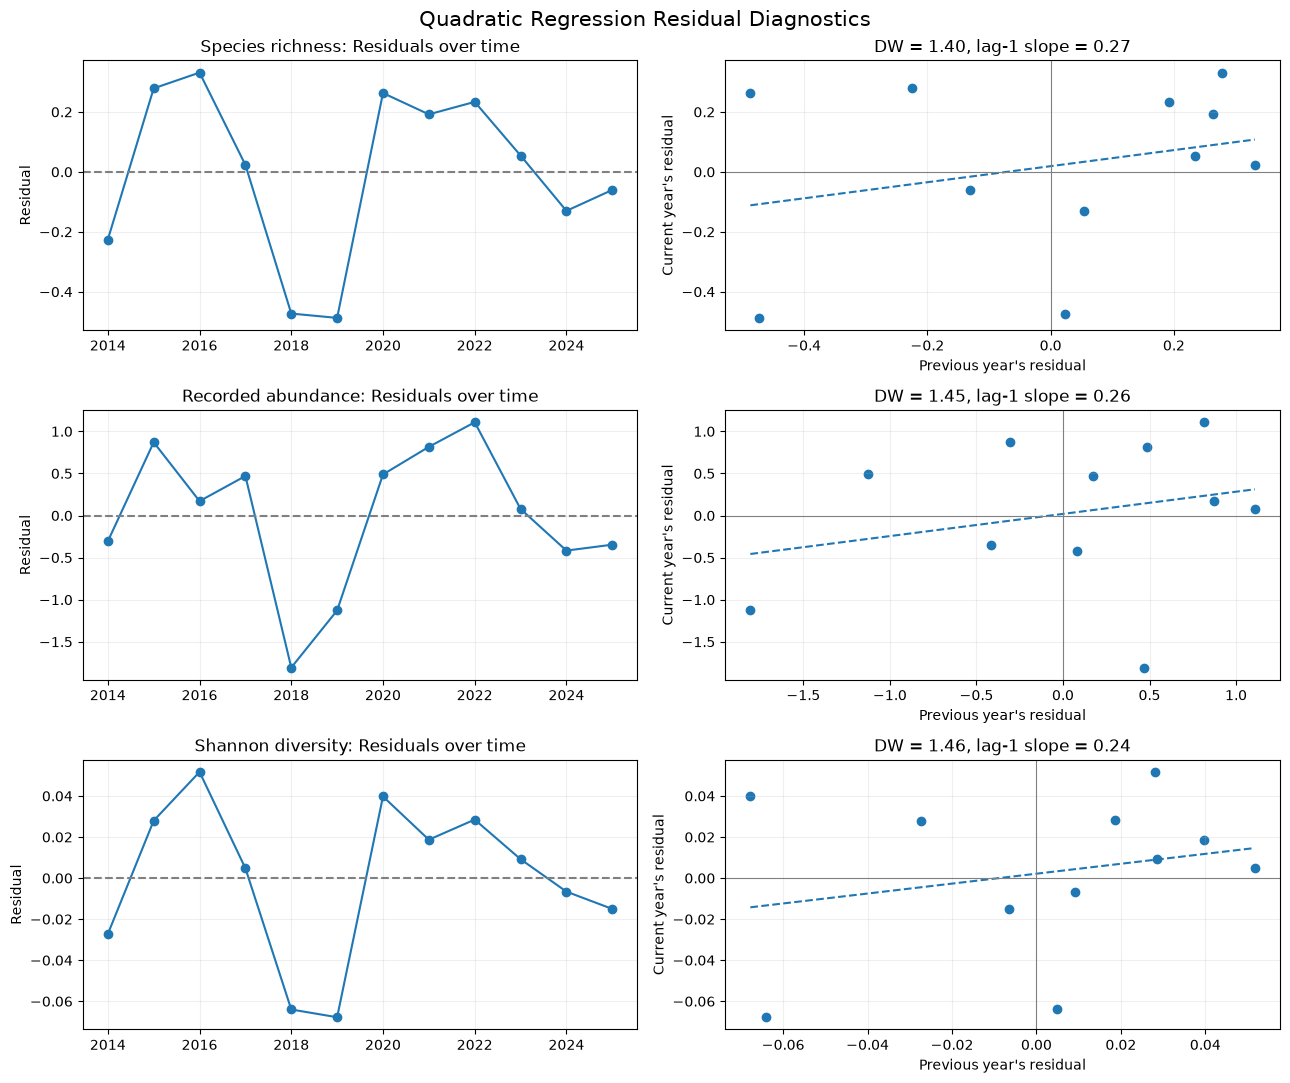

,indicator,dw,lag1_slope,lag1_correlation
0,richness,1.4017,0.2681,0.2763
1,recorded_abundance,1.4524,0.2637,0.2632
2,shannon,1.4590,0.2416,0.2461


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11))

ar1_results = []

for i, indicator in enumerate(indicators):

    residual_years = ci_tables[indicator]["year"].to_numpy()
    residuals = polynomial_models[indicator]["quadratic"]["residuals"]
    previous, current = residuals[:-1], residuals[1:]
    ar1 = stats.linregress(previous, current)
    dw = dw_statistics[indicator]

    ar1_results.append({
        "indicator": indicator,
        "dw": dw,
        "lag1_slope": ar1.slope,
        "lag1_correlation": ar1.rvalue
    })

    ax = axes[i, 0]

    ax.plot(residual_years, residuals, "o-")
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(f"{labels[indicator]}: Residuals over time")
    ax.set_ylabel("Residual")
    ax.grid(alpha=0.2)

    ax = axes[i, 1]

    ax.scatter(previous, current)

    x_line = np.linspace(previous.min(), previous.max(), 100)
    y_line = ar1.intercept + ar1.slope * x_line

    ax.plot(x_line, y_line, "--")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(
        f"DW = {dw:.2f}, lag-1 slope = {ar1.slope:.2f}"
    )
    ax.set_xlabel("Previous year's residual")
    ax.set_ylabel("Current year's residual")
    ax.grid(alpha=0.2)

fig.suptitle("Quadratic Regression Residual Diagnostics", fontsize=15)

plt.tight_layout()
fig.savefig(FIGURES / "quadratic_residual_diagnostics.png", bbox_inches="tight")
plt.show()

ar1_results = pd.DataFrame(ar1_results)

display(ar1_results.round(4))

### Interpretation of Residual Autocorrelation

Durbin–Watson values are 1.4017 for richness, 1.4524 for recorded abundance,
and 1.4590 for Shannon diversity. All suggest possible positive residual
autocorrelation, but do not establish its statistical significance with
only 12 observations. Conventional regression p-values therefore require
caution; the quadratic fits remain exploratory descriptions.

## 3. Sensitivity of Indicator Trends

Compare the original estimator with (1) routes having a valid value in every year and (2) complete visits without observer/time conflicts or repeated species entries. The fixed panel is selected separately for each indicator. Apply the same linear and quadratic models to all scenarios.

Percentile bootstrap intervals resample whole route histories (5,000 draws, fixed seed), preserving repeated-route dependence. They quantify route-sampling variability conditional on the observed years. They do not model shared island-wide year effects, spatial dependence or imperfect detection. OLS and F-test p-values remain exploratory.

In [13]:
def summarize_trend(year_values, values):
    """The same linear and quadratic fits, applied to any annual series."""
    t = np.asarray(year_values) - 2014
    y = np.asarray(values)
    result = stats.linregress(t, y)
    lower, upper = t_confidence_interval(result.slope, result.stderr, df=len(t) - 2)
    linear = fit_polynomial_trend(t, y, 1)
    quadratic = fit_polynomial_trend(t, y, 2)
    f_value, p_value = nested_f_test(linear, quadratic)
    beta = quadratic["coefficients"]
    turning = 2014 - beta[1] / (2 * beta[2]) if not np.isclose(beta[2], 0) else np.nan
    return {
        "slope": result.slope, "slope_ci_lower": lower, "slope_ci_upper": upper,
        "linear_p_value": result.pvalue, "r2_linear": linear["r_squared"],
        "quadratic_coefficient": beta[2], "quadratic_p_value": p_value,
        "r2_quadratic": quadratic["r_squared"],
        "turning_year": turning if 2014 <= turning <= 2025 else np.nan,
    }


def route_bootstrap(panel, seed=2026, repetitions=5000, comparisons=1):
    """Resample whole route histories, retaining missing years and equal route weights."""
    panel = panel.reindex(columns=years).dropna(how="all")
    values = panel.to_numpy(dtype=float)
    available = np.isfinite(values)
    rng = np.random.default_rng(seed)
    n_routes = len(panel)
    weights = rng.multinomial(n_routes, np.full(n_routes, 1 / n_routes), size=repetitions)
    denominators = weights @ available.astype(float)
    usable = (denominators > 0).all(axis=1)
    means = (weights[usable] @ np.nan_to_num(values)) / denominators[usable]
    if len(means) < 0.99 * repetitions:
        raise ValueError("Too many bootstrap samples have an unrepresented year")
    t = years - 2014
    centered_t = t - t.mean()
    slopes = means @ centered_t / np.sum(centered_t**2)
    design = np.column_stack([np.ones(len(t)), t, t**2])
    quadratic_coefficients = (means @ np.linalg.pinv(design).T)[:, 2]
    adjusted_tail = 0.05 / (2 * comparisons)
    return {
        "routes_resampled": n_routes, "bootstrap_repetitions": len(means),
        "slope_boot_lower": np.quantile(slopes, 0.025),
        "slope_boot_upper": np.quantile(slopes, 0.975),
        "slope_family_lower": np.quantile(slopes, adjusted_tail),
        "slope_family_upper": np.quantile(slopes, 1 - adjusted_tail),
        "quadratic_boot_lower": np.quantile(quadratic_coefficients, 0.025),
        "quadratic_boot_upper": np.quantile(quadratic_coefficients, 0.975),
    }

,indicator,scenario,routes_resampled,slope,slope_boot_lower,slope_boot_upper,quadratic_coefficient,quadratic_boot_lower,quadratic_boot_upper,turning_year
0,richness,all_routes,65,0.0735,0.0386,0.1086,-0.0343,-0.0429,-0.0258,2020.5714
1,richness,fixed_routes,39,0.0731,0.0341,0.1117,-0.0355,-0.0436,-0.0273,2020.5287
2,richness,complete_unambiguous,65,0.0733,0.0370,0.1085,-0.0329,-0.0414,-0.0244,2020.6129
3,recorded_abundance,all_routes,65,0.2041,0.0681,0.3398,-0.0898,-0.1192,-0.0608,2020.6367
4,recorded_abundance,fixed_routes,39,0.2169,0.0487,0.3978,-0.1052,-0.1432,-0.0705,2020.5309
5,recorded_abundance,complete_unambiguous,65,0.1849,0.0561,0.3139,-0.0965,-0.1299,-0.0642,2020.4584
6,shannon,all_routes,65,0.0077,0.0030,0.0122,-0.0038,-0.0051,-0.0026,2020.5098
7,shannon,fixed_routes,38,0.0069,0.0011,0.0123,-0.0041,-0.0054,-0.0029,2020.3284
8,shannon,complete_unambiguous,65,0.0082,0.0038,0.0126,-0.0034,-0.0045,-0.0023,2020.7122


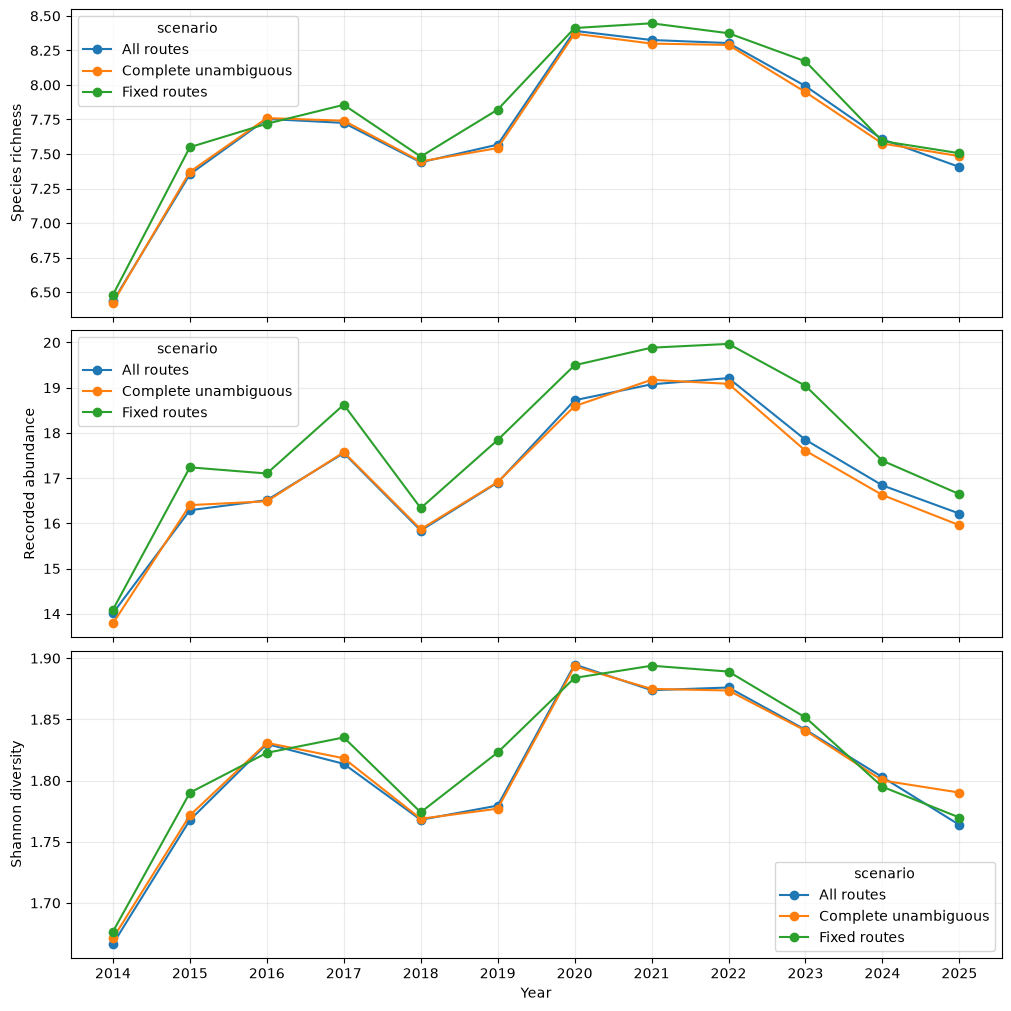

In [14]:
strict_points = points.loc[
    ~points["incomplete"] & ~points["metadata_conflict"] & ~points["repeated_species"]
]
strict_route_year = strict_points.groupby(["route_key", "year"])[indicators].mean().reset_index()
indicator_panels = {}
indicator_sensitivity_rows = []
indicator_sensitivity_annual = []

for indicator in indicators:
    baseline = route_year.pivot(index="route_key", columns="year", values=indicator).reindex(columns=years)
    strict = strict_route_year.pivot(index="route_key", columns="year", values=indicator).reindex(columns=years)
    panels = {"all_routes": baseline, "fixed_routes": baseline.dropna(), "complete_unambiguous": strict}
    indicator_panels[indicator] = panels
    for scenario, panel in panels.items():
        means = panel.mean()
        indicator_sensitivity_rows.append({
            "indicator": indicator, "scenario": scenario,
            **summarize_trend(years, means), **route_bootstrap(panel),
        })
        indicator_sensitivity_annual.append(pd.DataFrame({
            "year": years, "mean": means.to_numpy(), "routes": panel.count().to_numpy(),
            "indicator": indicator, "scenario": scenario,
        }))

indicator_sensitivity = pd.DataFrame(indicator_sensitivity_rows)
indicator_sensitivity_annual = pd.concat(indicator_sensitivity_annual, ignore_index=True)
display(indicator_sensitivity[[
    "indicator", "scenario", "routes_resampled", "slope", "slope_boot_lower", "slope_boot_upper",
    "quadratic_coefficient", "quadratic_boot_lower", "quadratic_boot_upper", "turning_year",
]].round(4))

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
for ax, indicator in zip(axes, indicators):
    comparison = indicator_sensitivity_annual.loc[indicator_sensitivity_annual["indicator"].eq(indicator)]
    comparison.pivot(index="year", columns="scenario", values="mean").rename(
        columns=lambda s: s.replace("_", " ").capitalize()
    ).plot(ax=ax, marker="o", ylabel=labels[indicator])
axes[-1].set(xlabel="Year", xticks=years)
fig.savefig(FIGURES / "indicator_trend_sensitivity.png")
plt.show()

The direction of linear and quadratic coefficients is stable across scenarios. Fixed panels contain 39 routes for richness/abundance and 38 for Shannon. Conditional route-bootstrap intervals need not agree with OLS intervals based on twelve annual errors; both uncertainty assumptions are reported.

## 4. Species-Level Evolution

We investigate the recorded detection frequencies of three
frequently observed species.

For each species, a point survey is assigned a value of 1 if
the species was detected, and 0 otherwise.

We calculate detection frequencies within each route-year,
then average across routes with equal weight.

Annual 95% confidence intervals use the route-level variation.
These estimates describe recorded detection, not true occupancy
or population abundance.

The species are frequent enough to estimate annual route-level detection frequencies. They provide common-species case studies, not a representative sample of all bird species.

In [15]:
observations = pd.read_csv(
    ROOT / "data/processed/observations_clean.csv", low_memory=False
)

# CSV files may serialize midnight with or without a time component.
observations["date"] = pd.to_datetime(observations["date"], format="mixed")
survey_key = ["route_key", "date", "visit", "point"]
matched_keys = observations[survey_key].drop_duplicates().merge(
    points[survey_key], on=survey_key, how="left", indicator=True, validate="one_to_one"
)
assert matched_keys["_merge"].eq("both").all(), "Detection records must match survey keys"

# Exclude surveys with inconsistent counts
valid_surveys = points.loc[
    ~points["count_problem"].fillna(True),
    survey_key + ["year"]
].copy()

# Fixed species selection used throughout the analysis.
selected_species = [
    "sucrier à ventre jaune",
    "viréo à moustaches",
    "sporophile cici"
]

print(
    observations.loc[
        observations["species_key"].str.contains(
            "sucrier|viréo|sporophile",
            case=False,
            na=False
        ),
        "species_key"
    ].value_counts().head(20)
)

species_key
sucrier à ventre jaune    10872
sporophile rougegorge      9161
sporophile cici            6342
viréo à moustaches         5837
sporophile curio            523
Name: count, dtype: int64


In [16]:
def species_detection_frequencies(observations, valid_surveys, species, survey_key):
    """Route-year detection frequencies, including valid surveys with no detection."""
    detected = (
        observations.loc[
            observations["species_key"].eq(species) & observations["selected_count"].gt(0),
            survey_key,
        ]
        .drop_duplicates()
        .assign(detected=1)
    )
    surveys = valid_surveys.merge(detected, on=survey_key, how="left", validate="one_to_one")
    surveys["detected"] = surveys["detected"].fillna(0)
    return (
        surveys.groupby(["route_key", "year"])["detected"]
        .mean()
        .reset_index()
    )


species_route_frequencies = {
    species: species_detection_frequencies(observations, valid_surveys, species, survey_key)
    for species in selected_species
}
species_results = {
    species: annual_confidence_intervals(frequencies, "detected")
    for species, frequencies in species_route_frequencies.items()
}

for species, table in species_results.items():
    print(f"\n{species.upper()}")
    display(table.round(4))


SUCRIER À VENTRE JAUNE


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.7401,40.0,0.0361,0.6670,0.8132
1,2015,0.7508,53.0,0.0265,0.6977,0.8039
2,2016,0.7451,59.0,0.0271,0.6908,0.7993
3,2017,0.7455,60.0,0.0285,0.6884,0.8026
4,2018,0.7458,64.0,0.0227,0.7004,0.7911
5,2019,0.7476,64.0,0.0264,0.6949,0.8003
6,2020,0.8089,63.0,0.0195,0.7700,0.8478
7,2021,0.7806,63.0,0.0247,0.7312,0.8299
8,2022,0.7836,63.0,0.0245,0.7346,0.8325
9,2023,0.7606,64.0,0.0289,0.7029,0.8183



VIRÉO À MOUSTACHES


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.2668,40.0,0.0407,0.1846,0.3490
1,2015,0.3797,53.0,0.0360,0.3075,0.4519
2,2016,0.4008,59.0,0.0353,0.3302,0.4714
3,2017,0.4008,60.0,0.0352,0.3303,0.4712
4,2018,0.3651,64.0,0.0315,0.3021,0.4281
5,2019,0.4086,64.0,0.0350,0.3388,0.4785
6,2020,0.4526,63.0,0.0370,0.3785,0.5266
7,2021,0.4223,63.0,0.0369,0.3485,0.4962
8,2022,0.4596,63.0,0.0361,0.3874,0.5317
9,2023,0.4470,64.0,0.0377,0.3716,0.5223



SPOROPHILE CICI


,year,mean,n,se,ci_lower,ci_upper
0,2014,0.4432,40.0,0.0452,0.3518,0.5346
1,2015,0.4643,53.0,0.0396,0.3847,0.5438
2,2016,0.4818,59.0,0.0366,0.4086,0.5550
3,2017,0.4513,60.0,0.0417,0.3678,0.5348
4,2018,0.4543,64.0,0.0327,0.3889,0.5197
5,2019,0.4498,64.0,0.0361,0.3776,0.5219
6,2020,0.4478,63.0,0.0340,0.3798,0.5159
7,2021,0.4906,63.0,0.0363,0.4180,0.5631
8,2022,0.4872,63.0,0.0382,0.4107,0.5636
9,2023,0.4761,64.0,0.0354,0.4053,0.5468


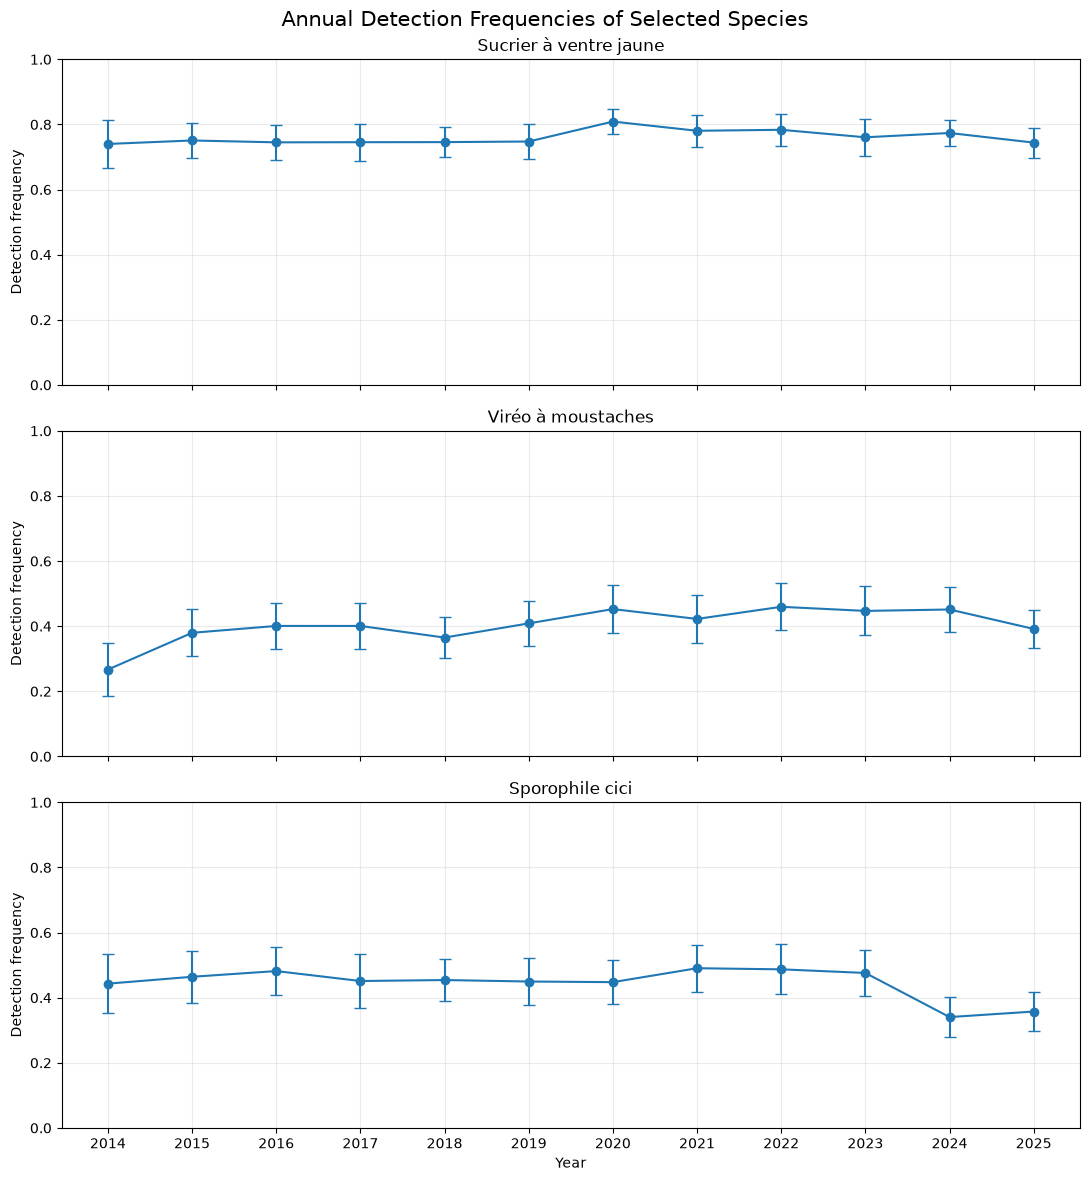

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

for ax, species in zip(axes, selected_species):
    table = species_results[species]

    ax.errorbar(
        table["year"],
        table["mean"],
        yerr=[
            table["mean"] - table["ci_lower"],
            table["ci_upper"] - table["mean"]
        ],
        fmt="o-",
        capsize=4
    )

    ax.set_ylabel("Detection frequency")
    ax.set_title(species.capitalize())
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(range(2014, 2026))

fig.suptitle(
    "Annual Detection Frequencies of Selected Species",
    fontsize=15
)

plt.tight_layout()
fig.savefig(FIGURES / "species_detection_intervals.png", bbox_inches="tight")
plt.show()

In [18]:
species_models = {}
species_trends = []
for species, table in species_results.items():
    result = stats.linregress(table["year"] - 2014, table["mean"])
    species_models[species] = result
    lower, upper = t_confidence_interval(result.slope, result.stderr, df=len(table) - 2)
    species_trends.append({
        "species": species,
        "slope": result.slope,
        "r_squared": result.rvalue**2,
        "p_value": result.pvalue,
        "slope_ci_lower": lower, "slope_ci_upper": upper,
    })

species_trends = pd.DataFrame(species_trends)
species_trends["p_bonferroni"] = (species_trends["p_value"] * len(selected_species)).clip(upper=1)
display(species_trends.round(4))

,species,slope,r_squared,p_value,slope_ci_lower,slope_ci_upper,p_bonferroni
0,sucrier à ventre jaune,0.0025,0.1774,0.1728,-0.0013,0.0063,0.5183
1,viréo à moustaches,0.0100,0.4585,0.0156,0.0023,0.0176,0.0467
2,sporophile cici,-0.0063,0.2266,0.1177,-0.0146,0.0019,0.3531


### Interpretation of Species-Level Trends

Only Viréo à moustaches passes the conventional OLS 5% threshold after Bonferroni adjustment across three species. These results assume independent annual errors. Sections 4.2–4.3 examine residuals, repeated-route uncertainty and route composition.

### 4.1 Paired-Route Comparison: 2014 vs. 2025

To investigate whether species-level changes persist when
monitoring locations are held constant, we compare detection
frequencies within routes surveyed in both 2014 and 2025.

For each species, we calculate the difference between its
2025 and 2014 detection frequencies at each eligible route.

We then estimate the mean paired difference, construct a
95% Student's t-confidence interval, and test whether
the mean change differs from zero.

This comparison reduces sensitivity to changes in route
composition, but does not control for changes in detection
conditions or survey effort within routes.

In [19]:
paired_species_data = {}
for species, frequencies in species_route_frequencies.items():
    paired = (
        frequencies.loc[frequencies["year"].isin([2014, 2025])]
        .pivot(index="route_key", columns="year", values="detected")
        .dropna(subset=[2014, 2025])
    )
    paired["difference"] = paired[2025] - paired[2014]
    paired_species_data[species] = paired
    print(f"{species}: {len(paired)} paired routes")

sucrier à ventre jaune: 40 paired routes
viréo à moustaches: 40 paired routes
sporophile cici: 40 paired routes


In [20]:
def summarize_paired_change(paired, start_year=2014, end_year=2025):
    """Summarize complete endpoint pairs with a t interval and paired t-test."""
    change = mean_confidence_interval(paired[end_year] - paired[start_year])
    test = stats.ttest_rel(paired[end_year], paired[start_year])
    return {
        "routes": len(paired),
        f"mean_{start_year}": paired[start_year].mean(),
        f"mean_{end_year}": paired[end_year].mean(),
        "change": change["mean"],
        "ci_lower": change["ci_lower"],
        "ci_upper": change["ci_upper"],
        "p_value": test.pvalue,
    }


paired_results = pd.DataFrame([
    {"species": species, **summarize_paired_change(paired)}
    for species, paired in paired_species_data.items()
])
paired_results["p_bonferroni"] = (paired_results["p_value"] * len(selected_species)).clip(upper=1)
display(paired_results.round(4))

,species,routes,mean_2014,mean_2025,change,ci_lower,ci_upper,p_value,p_bonferroni
0,sucrier à ventre jaune,40,0.7401,0.7468,0.0067,-0.0737,0.0871,0.8672,1.0000
1,viréo à moustaches,40,0.2668,0.3993,0.1324,0.0612,0.2037,0.0006,0.0017
2,sporophile cici,40,0.4432,0.3853,-0.0579,-0.1305,0.0147,0.1149,0.3446


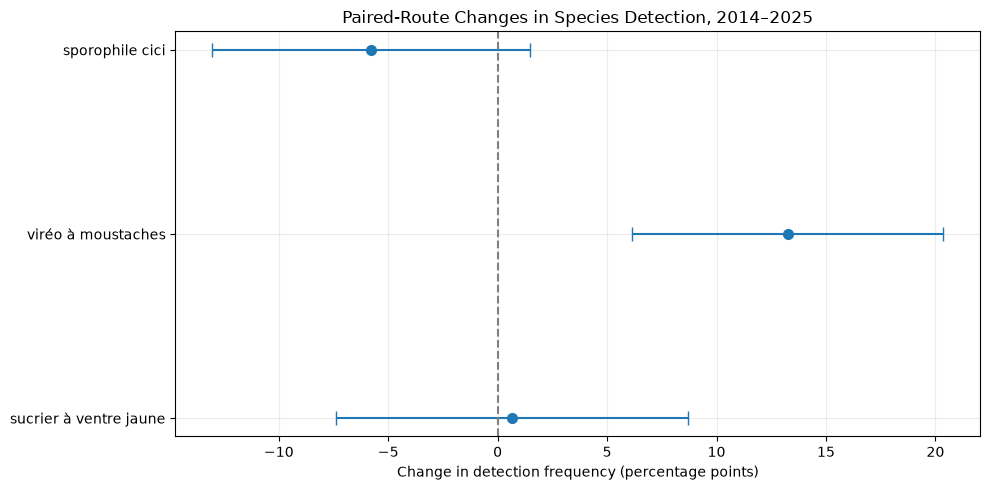

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))

y_pos = np.arange(len(selected_species))

changes = paired_results["change"]

lower_error = changes - paired_results["ci_lower"]
upper_error = paired_results["ci_upper"] - changes

ax.errorbar(
    changes * 100,
    y_pos,
    xerr=[lower_error * 100, upper_error * 100],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_yticks(y_pos)
ax.set_yticklabels(selected_species)
ax.set_xlabel("Change in detection frequency (percentage points)")
ax.set_title("Paired-Route Changes in Species Detection, 2014–2025")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
fig.savefig(FIGURES / "paired_species_changes.png", bbox_inches="tight")
plt.show()

### Interpretation of Paired-Route Changes

Among 40 paired routes, Viréo à moustaches increases by 13.24 percentage points (95% CI: 6.12–20.37; Bonferroni-adjusted p = 0.0017). Neither other species has a clear endpoint change. Endpoint comparisons and full-period slopes answer different questions.

### 4.2 Species Regression Diagnostics

Inspect residuals against time and fitted values, plus normal Q–Q plots. Durbin–Watson and Shapiro–Wilk are descriptive checks with only 12 annual values; a large diagnostic p-value does not validate independence.

,species,n_years,durbin_watson,shapiro_p_value
0,sucrier à ventre jaune,12,1.5184,0.0992
1,viréo à moustaches,12,1.3666,0.0353
2,sporophile cici,12,1.1098,0.5001


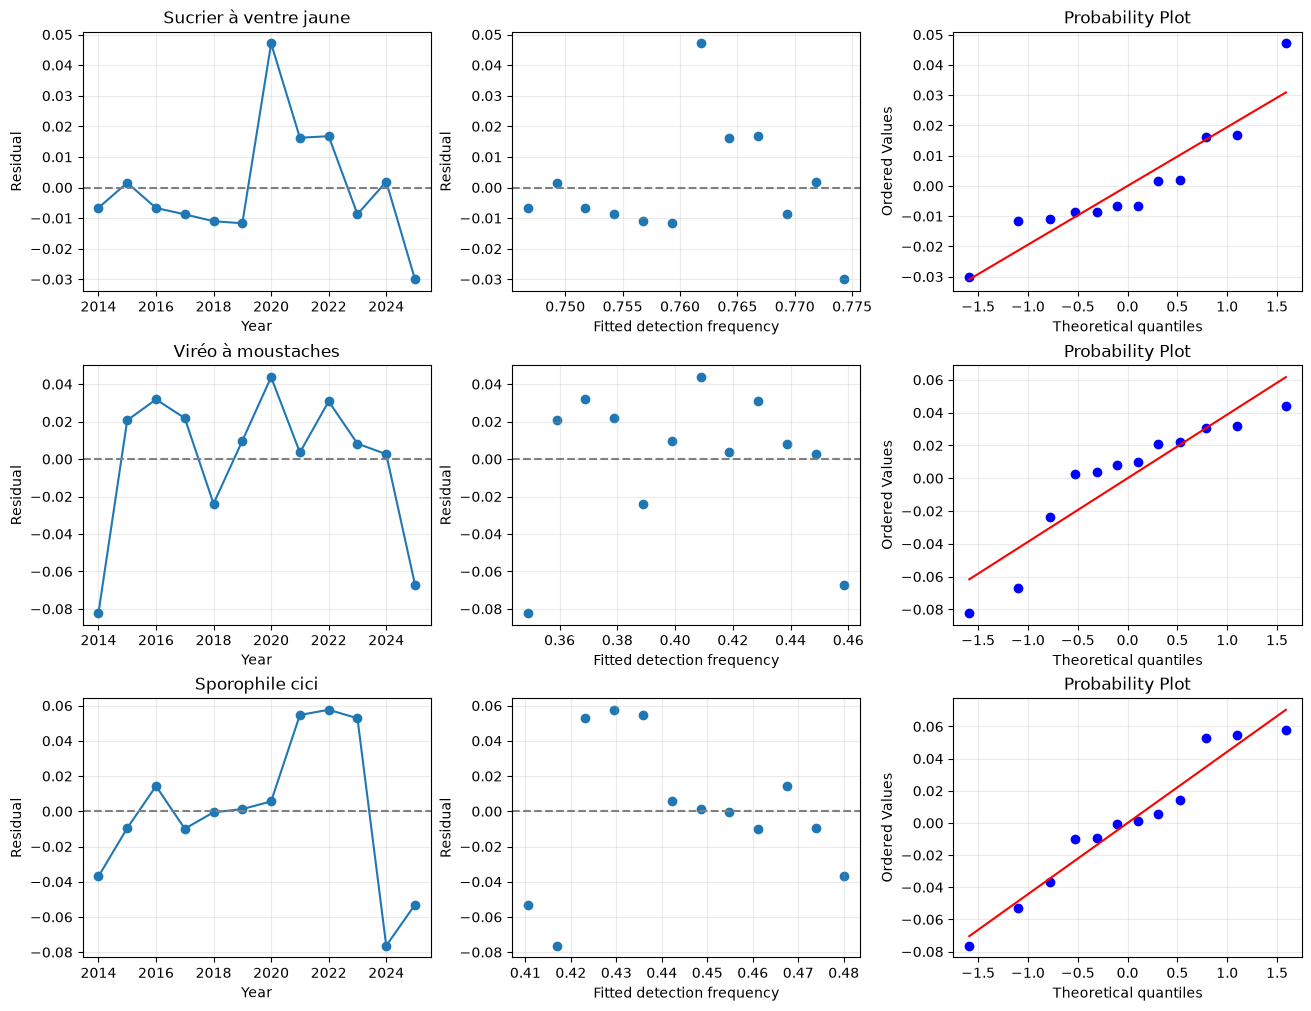

In [22]:
species_diagnostics_rows = []
fig, axes = plt.subplots(3, 3, figsize=(13, 10), layout="constrained")
for row, species in enumerate(selected_species):
    table = species_results[species].sort_values("year")
    model = species_models[species]
    fitted = model.intercept + model.slope * (table["year"] - 2014)
    residuals = table["mean"].to_numpy() - fitted.to_numpy()
    species_diagnostics_rows.append({
        "species": species, "n_years": len(table),
        "durbin_watson": durbin_watson(residuals),
        "shapiro_p_value": stats.shapiro(residuals).pvalue,
    })
    axes[row, 0].plot(table["year"], residuals, "o-")
    axes[row, 0].axhline(0, color="gray", linestyle="--")
    axes[row, 0].set(title=species.capitalize(), xlabel="Year", ylabel="Residual")
    axes[row, 1].scatter(fitted, residuals)
    axes[row, 1].axhline(0, color="gray", linestyle="--")
    axes[row, 1].set(xlabel="Fitted detection frequency", ylabel="Residual")
    stats.probplot(residuals, dist="norm", plot=axes[row, 2])
species_diagnostics = pd.DataFrame(species_diagnostics_rows)
display(species_diagnostics.round(4))
fig.savefig(FIGURES / "species_regression_diagnostics.png")
plt.show()

### 4.3 Species Trend Sensitivity and Route Bootstrap

Repeat detection-frequency trends with fixed routes and complete, unambiguous surveys. Bootstrap whole route histories as in Section 3. Alongside ordinary 95% intervals, use 98.33% marginal slope intervals for a Bonferroni family of three species within each scenario. Scenario comparisons are sensitivity checks, not independent confirmatory tests.

,species,scenario,routes_resampled,slope,slope_boot_lower,slope_boot_upper,slope_family_lower,slope_family_upper,family_interval_excludes_zero
0,sucrier à ventre jaune,all_routes,65,0.0025,-0.0022,0.0073,-0.0033,0.0085,False
1,sucrier à ventre jaune,fixed_routes,39,0.0009,-0.0043,0.0061,-0.0054,0.0074,False
2,sucrier à ventre jaune,complete_unambiguous,65,0.0027,-0.0019,0.0075,-0.0029,0.0085,False
3,viréo à moustaches,all_routes,65,0.0100,0.0053,0.0149,0.0040,0.0159,True
4,viréo à moustaches,fixed_routes,39,0.0104,0.0057,0.0153,0.0050,0.0162,True
5,viréo à moustaches,complete_unambiguous,65,0.0110,0.0061,0.0161,0.0049,0.0172,True
6,sporophile cici,all_routes,65,-0.0063,-0.0113,-0.0014,-0.0124,-0.0004,True
7,sporophile cici,fixed_routes,39,-0.0042,-0.0096,0.0016,-0.0111,0.0028,False
8,sporophile cici,complete_unambiguous,65,-0.0056,-0.0107,-0.0006,-0.0119,0.0004,False


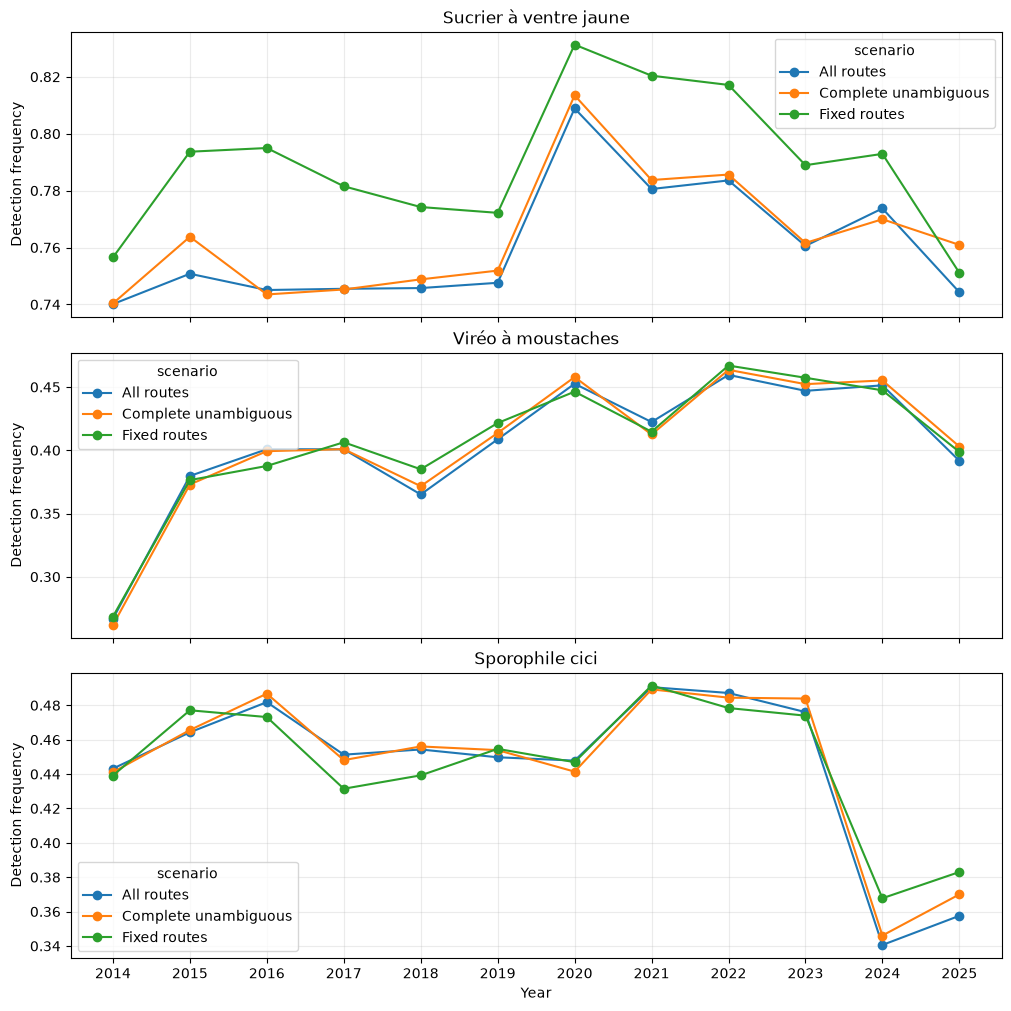

In [23]:
strict_valid_surveys = strict_points.loc[
    ~strict_points["count_problem"].fillna(True), survey_key + ["year"]
]
species_sensitivity_rows = []
species_sensitivity_annual = []
for species in selected_species:
    frequencies = species_route_frequencies[species]
    baseline = frequencies.pivot(index="route_key", columns="year", values="detected").reindex(columns=years)
    strict_frequencies = species_detection_frequencies(observations, strict_valid_surveys, species, survey_key)
    strict = strict_frequencies.pivot(index="route_key", columns="year", values="detected").reindex(columns=years)
    for scenario, panel in {"all_routes": baseline, "fixed_routes": baseline.dropna(), "complete_unambiguous": strict}.items():
        means = panel.mean()
        species_sensitivity_rows.append({
            "species": species, "scenario": scenario,
            **summarize_trend(years, means), **route_bootstrap(panel, comparisons=len(selected_species)),
        })
        species_sensitivity_annual.append(pd.DataFrame({
            "year": years, "mean": means.to_numpy(), "routes": panel.count().to_numpy(),
            "species": species, "scenario": scenario,
        }))
species_sensitivity = pd.DataFrame(species_sensitivity_rows)
species_sensitivity_annual = pd.concat(species_sensitivity_annual, ignore_index=True)
species_sensitivity["family_interval_excludes_zero"] = (
    species_sensitivity["slope_family_lower"].gt(0) | species_sensitivity["slope_family_upper"].lt(0)
)
display(species_sensitivity[[
    "species", "scenario", "routes_resampled", "slope", "slope_boot_lower", "slope_boot_upper",
    "slope_family_lower", "slope_family_upper", "family_interval_excludes_zero",
]].round(4))

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
for ax, species in zip(axes, selected_species):
    comparison = species_sensitivity_annual.loc[species_sensitivity_annual["species"].eq(species)]
    comparison.pivot(index="year", columns="scenario", values="mean").rename(
        columns=lambda s: s.replace("_", " ").capitalize()
    ).plot(ax=ax, marker="o", title=species.capitalize(), ylabel="Detection frequency")
axes[-1].set(xlabel="Year", xticks=years)
fig.savefig(FIGURES / "species_trend_sensitivity.png")
plt.show()

Viréo à moustaches retains a positive slope and family-adjusted route-bootstrap interval above zero in every scenario. Sporophile cici does not retain an interval excluding zero under fixed-route or strict-survey inclusion. Sucrier à ventre jaune has no clear slope. These conclusions are conditional on the recorded years and route-independence assumption.

In [24]:
species_abundance = {}

for species in selected_species:

    # Sum recorded counts within each survey
    counts = (
        observations.loc[
            observations["species_key"] == species
        ]
        .groupby(survey_key)["selected_count"]
        .sum(min_count=1)
        .reset_index()
    )

    # Include valid surveys without the species
    species_surveys = valid_surveys.merge(
        counts,
        on=survey_key,
        how="left",
        validate="one_to_one"
    )

    species_surveys["selected_count"] = (
        species_surveys["selected_count"].fillna(0)
    )

    route_abundance = (
        species_surveys
        .groupby(["route_key", "year"])["selected_count"]
        .mean()
        .reset_index()
    )

    species_abundance[species] = annual_confidence_intervals(
        route_abundance, "selected_count"
    )

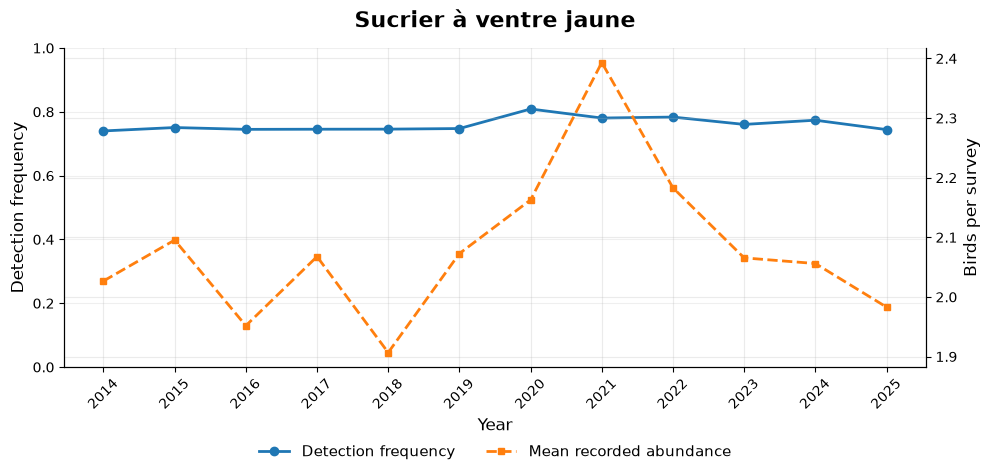

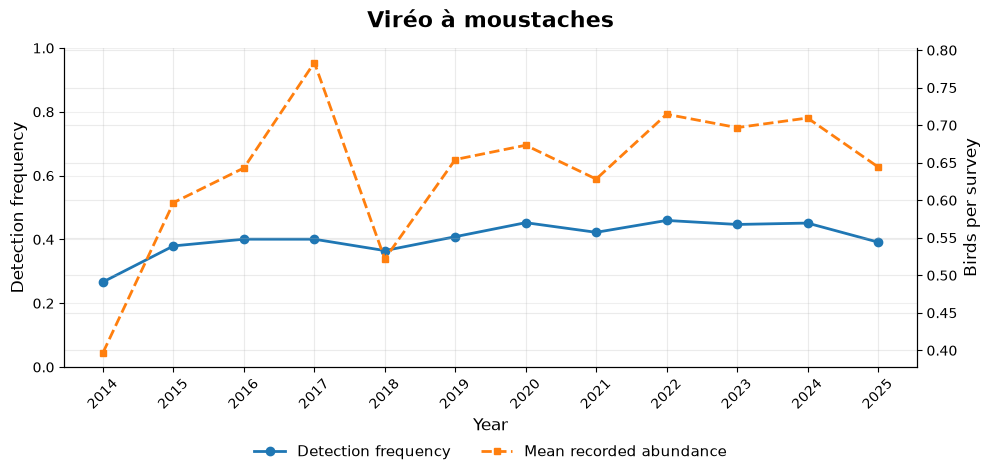

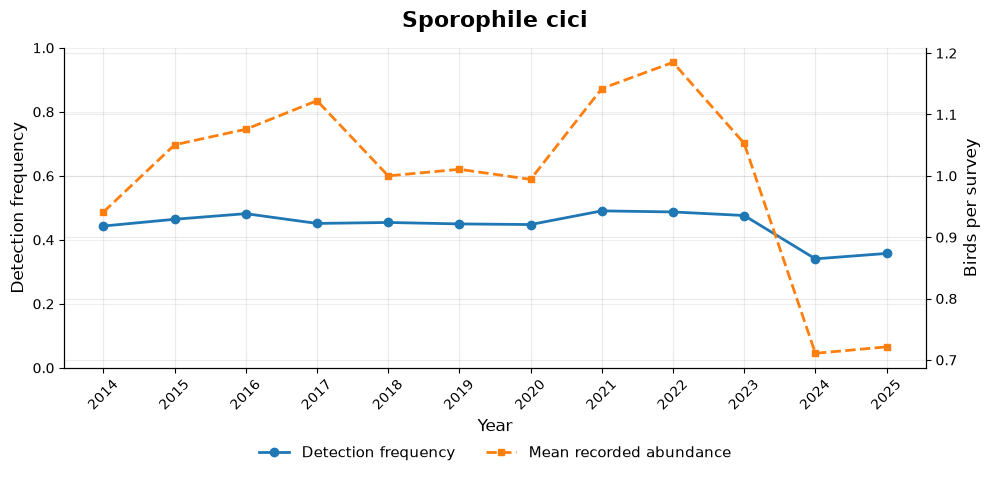

In [25]:
for i, species in enumerate(selected_species):

    detection = species_results[species].sort_values("year")
    abundance = species_abundance[species].sort_values("year")

    fig, ax = plt.subplots(figsize=(10, 5))

    # Left axis: detection frequency
    line1, = ax.plot(
        detection["year"],
        detection["mean"],
        "o-",
        color="C0",
        linewidth=2,
        markersize=6,
        label="Detection frequency"
    )

    ax.set_ylabel("Detection frequency", fontsize=12)
    ax.set_ylim(0, 1)

    # Right axis: recorded abundance
    ax2 = ax.twinx()

    line2, = ax2.plot(
        abundance["year"],
        abundance["mean"],
        "s--",
        color="C1",
        linewidth=2,
        markersize=5,
        label="Mean recorded abundance"
    )

    ax2.set_ylabel("Birds per survey", fontsize=12)

    ax.set_title(
        species.capitalize(),
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_xticks(range(2014, 2026))
    ax.tick_params(axis="x", rotation=45)

    ax.legend(
        handles=[line1, line2],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
        fontsize=11
    )

    ax.grid(axis="y", alpha=0.2)

    ax.spines["top"].set_visible(False)
    ax2.spines["top"].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        FIGURES / f"species_comparison_{i+1}.png",
        bbox_inches="tight"
    )

    plt.show()

## 5. Export Results

Tables contain full-precision estimates; displayed values are rounded. All figures are saved in `figures/`, and the following tables in `results/`.

In [26]:
annual_intervals = pd.concat([
    table.assign(indicator=indicator) for indicator, table in ci_tables.items()
], ignore_index=True)
species_intervals = pd.concat([
    table.assign(species=species) for species, table in species_results.items()
], ignore_index=True)
species_abundance_intervals = pd.concat([
    table.assign(species=species) for species, table in species_abundance.items()
], ignore_index=True)
paired_route_details = pd.concat([
    table.reset_index().assign(species=species) for species, table in paired_species_data.items()
], ignore_index=True)
export_tables = {
    "indicator_confidence_intervals": annual_intervals,
    "indicator_linear_trends": trend_results,
    "indicator_quadratic_trends": quadratic_results,
    "indicator_quadratic_diagnostics": ar1_results,
    "indicator_trend_sensitivity": indicator_sensitivity,
    "indicator_sensitivity_annual": indicator_sensitivity_annual,
    "species_detection_intervals": species_intervals,
    "species_abundance_intervals": species_abundance_intervals,
    "species_linear_trends": species_trends,
    "species_regression_diagnostics": species_diagnostics,
    "species_trend_sensitivity": species_sensitivity,
    "species_sensitivity_annual": species_sensitivity_annual,
    "paired_species_changes": paired_results,
    "paired_species_route_details": paired_route_details,
}
for name, table in export_tables.items():
    table.to_csv(RESULTS / f"{name}.csv", index=False)
print(f"Exported {len(export_tables)} statistical tables to {RESULTS}")

# Validate the estimand and probability denominators before interpreting results.
assert len(annual_intervals) == 36
assert len(species_intervals) == 36
assert indicator_sensitivity.shape[0] == 9
assert species_sensitivity.shape[0] == 9
assert species_intervals["mean"].between(0, 1).all()
for indicator in indicators:
    baseline = indicator_sensitivity.query("indicator == @indicator and scenario == 'all_routes'").iloc[0]
    assert np.isclose(baseline["slope"], linear_models[indicator].slope)
for species in selected_species:
    baseline = species_sensitivity.query("species == @species and scenario == 'all_routes'").iloc[0]
    assert np.isclose(baseline["slope"], species_models[species].slope)
    frequencies = species_route_frequencies[species]
    assert frequencies["detected"].between(0, 1).all()
assert indicator_sensitivity["bootstrap_repetitions"].eq(5000).all()
assert species_sensitivity["bootstrap_repetitions"].eq(5000).all()
print("Baseline estimates, survey denominators and bootstrap replication checks passed.")

Exported 14 statistical tables to /Users/masmits/Documents/CORE/APLICATIONS/PARIS_SACLAY_WORK/M1/T1/birds-biodiversity/results
Baseline estimates, survey denominators and bootstrap replication checks passed.


## 6. Synthesis and Limitations

All three indicators show a rise followed by a fall; the negative quadratic term and fitted peak around 2020–2021 persist across inclusion scenarios. This shape should not be reduced to a constant long-run increase. OLS intervals describe annual-error uncertainty; route bootstrap intervals describe route-sampling uncertainty conditional on the observed years.

Viréo à moustaches shows the most consistent increase in recorded detection: its slope stays positive across scenarios, and the paired endpoint comparison agrees. The decline suggested for Sporophile cici is sensitive to route composition and inclusion rules. Sucrier à ventre jaune has no clear directional change.

Changing coverage, observer turnover and survey conditions are plausible operational explanations. Habitat or resource changes are ecological hypotheses; none is established as a cause here. Keep a stable route/point network, record complete effort, and verify inconsistent counts and weather codes. Shared year effects, spatial dependence and imperfect detection remain limitations.